In [50]:
import pandas as pd
import sqlite3 as sql

In [51]:
conn = sql.connect("chinook (1).db")

def sql_query(q):
    return pd.read_sql_query(q,conn)

In [52]:
sql_query("select *from sqlite_master")

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


In [53]:
sql_query ("select *from sqlite_master where type = 'table'")

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


<img src = "WhatsApp Image 2026-10-04 at 10.27.41 AM.jpeg" width = "60%" />

## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

In [54]:
import matplotlib.pyplot as plt

In [55]:
q = '''Select g.Name AS Genre,
    COUNT(t.Track_Id) AS Total_Tracks
FROM Track t JOIN Genre g
ON t.Genre_Id = g.Genre_Id
GROUP BY g.Name
ORDER BY Total_Tracks DESC
LIMIT 10;'''
sql_query(q)

,Genre,Total_Tracks
0,Rock,1297
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61


In [56]:
df = sql_query(q)

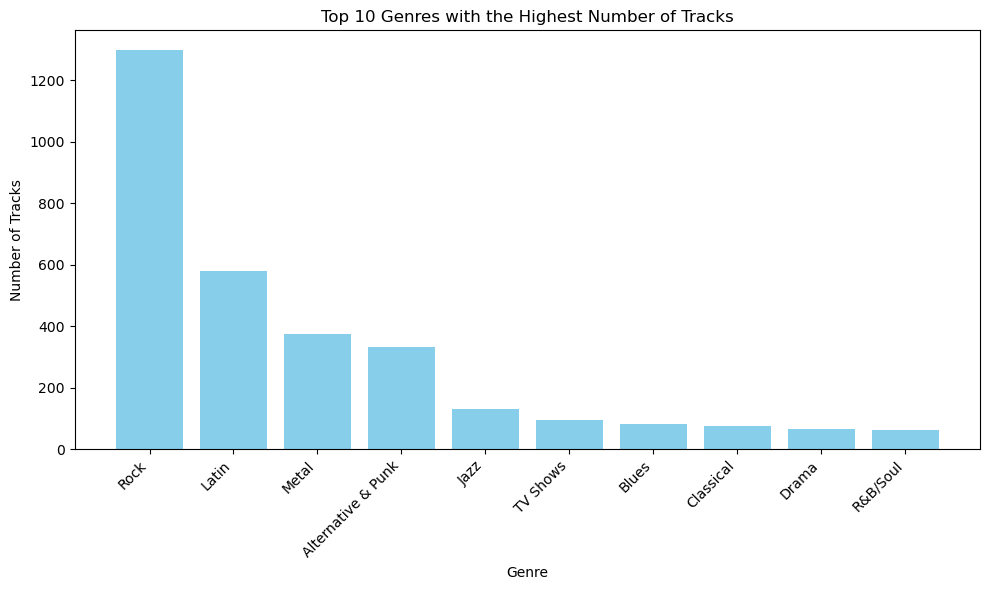

In [57]:
plt.figure(figsize=(10, 6))
plt.bar(df['Genre'], df['Total_Tracks'], color='skyblue')

plt.title('Top 10 Genres with the Highest Number of Tracks')
plt.xlabel('Genre')
plt.ylabel('Number of Tracks')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## Q2. Write a query to list the top 10 albums that contain the most tracks.

In [60]:
q = """Select a.Title AS Album,
    COUNT(t.Track_Id) AS Total_Tracks
FROM Album a JOIN Track t
    ON a.Album_Id = t.Album_Id
GROUP BY a.Album_Id, a.Title
ORDER BY Total_Tracks DESC
LIMIT 10;"""
sql_query(q)

,Album,Total_Tracks
0,Greatest Hits,57
1,Minha Historia,34
2,Unplugged,30
3,"Lost, Season 3",26
4,"Lost, Season 1",25
5,"The Office, Season 3",25
6,My Way: The Best Of Frank Sinatra [Disc 1],24
7,"Lost, Season 2",24
8,"Battlestar Galactica (Classic), Season 1",24
9,Afrociberdelia,23


## Q3. Write a query to find the top 10 customers who spent the most money.

In [63]:
q = """ Select c.Customer_Id, c.First_Name || ' ' || c.Last_Name AS Customer_Name,
    ROUND(SUM(il.Unit_Price * il.Quantity), 2) AS Total_Spent
FROM Customer c JOIN Invoice i
ON c.Customer_Id = i.Customer_Id
JOIN Invoice_Line il ON i.Invoice_Id = il.Invoice_Id
GROUP BY c.Customer_Id, c.First_Name, c.Last_Name
ORDER BY Total_Spent DESC LIMIT 10;"""
sql_query(q)

,customer_id,Customer_Name,Total_Spent
0,5,František Wichterlová,144.54
1,6,Helena Holý,128.70
2,46,Hugh O'Reilly,114.84
3,58,Manoj Pareek,111.87
4,1,Luís Gonçalves,108.90
5,13,Fernanda Ramos,106.92
6,34,João Fernandes,102.96
7,3,François Tremblay,99.99
8,42,Wyatt Girard,99.99
9,17,Jack Smith,98.01


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [64]:
q = """ Select ar.Name AS Artist,
    ROUND(SUM(il.Unit_Price * il.Quantity), 2) AS Total_Revenue
FROM Artist ar JOIN Album al
ON ar.Artist_Id = al.Artist_Id
JOIN Track t ON al.Album_Id = t.Album_Id
JOIN Invoice_Line il ON t.Track_Id = il.Track_Id
GROUP BY ar.Artist_Id, ar.Name
ORDER BY Total_Revenue DESC LIMIT 5;"""
sql_query(q)

,Artist,Total_Revenue
0,Queen,190.08
1,Jimi Hendrix,185.13
2,Nirvana,128.70
3,Red Hot Chili Peppers,128.70
4,Pearl Jam,127.71


## Q5. Countries by Average Revenue per Invoice

In [65]:
q = """ Select Billing_Country AS Country,
ROUND(AVG(Total), 2) AS Average_Revenue_Per_Invoice
FROM Invoice
GROUP BY Billing_Country
ORDER BY Average_Revenue_Per_Invoice DESC """
sql_query(q)

,Country,Average_Revenue_Per_Invoice
0,Czech Republic,9.11
1,Spain,8.91
2,Ireland,8.83
3,United Kingdom,8.77
4,India,8.72
5,Belgium,8.63
6,Germany,8.16
7,Australia,8.12
8,Norway,8.03
9,USA,7.94


## Q6. Write a query to find the media type with number of tracks.


In [66]:
q = """ Select m.Name AS Media_Type,
COUNT(t.Track_Id) AS Number_of_Tracks
FROM Media_Type m JOIN Track t
ON m.Media_Type_Id = t.Media_Type_Id
GROUP BY m.Media_Type_Id, m.Name
ORDER BY Number_of_Tracks DESC;
"""
sql_query(q)

,Media_Type,Number_of_Tracks
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


## Q7. Which artists have released tracks in more than one genre?

In [67]:
q = """ Select ar.Name AS Artist,
COUNT(DISTINCT t.Genre_Id) AS Number_of_Genres
FROM Artist ar JOIN Album al
ON ar.Artist_Id = al.Artist_Id
JOIN Track t ON al.Album_Id = t.Album_Id
GROUP BY ar.Artist_Id, ar.Name
HAVING COUNT(DISTINCT t.Genre_Id) > 1
ORDER BY Number_of_Genres DESC"""
sql_query(q)

,Artist,Number_of_Genres
0,Iron Maiden,4
1,Audioslave,3
2,Various Artists,3
3,Gilberto Gil,3
4,Jamiroquai,3
5,Lenny Kravitz,3
6,Battlestar Galactica,3
7,Antônio Carlos Jobim,2
8,Eric Clapton,2
9,Faith No More,2


## Q8. Write a query to list the top 10 longest tracks by duration.

In [68]:
q = """Select Name AS Track_Name,
    Milliseconds, ROUND(Milliseconds / 60000.0, 2) AS Duration_Minutes
FROM Track ORDER BY Milliseconds DESC LIMIT 10"""
sql_query(q)

,Track_Name,milliseconds,Duration_Minutes
0,Occupation / Precipice,5286953,88.12
1,Through a Looking Glass,5088838,84.81
2,"Greetings from Earth, Pt. 1",2960293,49.34
3,The Man With Nine Lives,2956998,49.28
4,"Battlestar Galactica, Pt. 2",2956081,49.27
5,"Battlestar Galactica, Pt. 1",2952702,49.21
6,Murder On the Rising Star,2935894,48.93
7,"Battlestar Galactica, Pt. 3",2927802,48.80
8,Take the Celestra,2927677,48.79
9,Fire In Space,2926593,48.78


## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

In [70]:
q = """Select ar.Name AS Artist,
ROUND(SUM(il.Unit_Price * il.Quantity), 2) AS Revenue FROM Artist ar
JOIN Album al ON ar.Artist_Id = al.Artist_Id
JOIN Track t ON al.Album_Id = t.Album_Id
JOIN Invoice_Line il ON t.Track_Id = il.Track_Id
GROUP BY ar.Artist_Id, ar.Name
ORDER BY Revenue DESC LIMIT 5;"""
sql_query(q)

,Artist,Revenue
0,Queen,190.08
1,Jimi Hendrix,185.13
2,Nirvana,128.70
3,Red Hot Chili Peppers,128.70
4,Pearl Jam,127.71


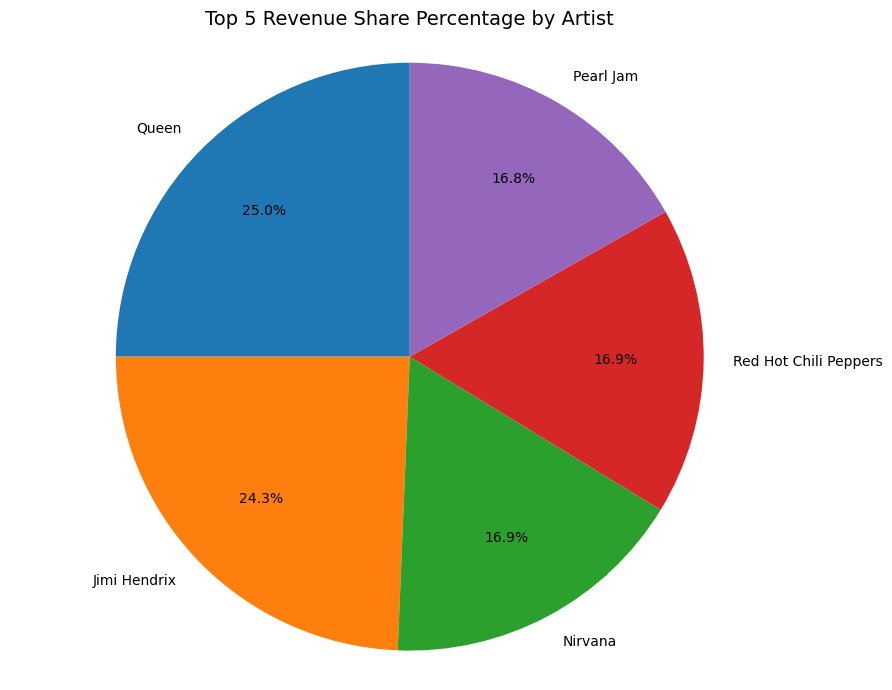

In [74]:
plt.figure(figsize=(9, 7))

plt.pie(sql_query(q)["Revenue"],
    labels=sql_query(q)["Artist"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.7)

plt.title("Top 5 Revenue Share Percentage by Artist", fontsize=14)
plt.axis("equal")
plt.tight_layout()
plt.show()

## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

In [76]:
q = """Select i.Billing_Country AS Country, g.Name AS Genre,
ROUND(SUM(il.Unit_Price * il.Quantity), 2) AS Revenue
FROM Invoice i JOIN Invoice_Line il ON i.Invoice_Id = il.Invoice_Id
JOIN Track t ON il.Track_Id = t.Track_Id
JOIN Genre g ON t.Genre_Id = g.Genre_Id
WHERE g.Name IN ('Rock', 'Latin', 'Metal')
GROUP BY i.Billing_Country, g.Name
ORDER BY Country, Genre;"""
sql_query(q)

,Country,Genre,Revenue
0,Argentina,Latin,1.98
1,Argentina,Metal,1.98
2,Argentina,Rock,10.89
3,Australia,Latin,1.98
4,Australia,Metal,13.86
...,...,...,...
65,USA,Metal,122.76
66,USA,Rock,555.39
67,United Kingdom,Latin,6.93
68,United Kingdom,Metal,30.69


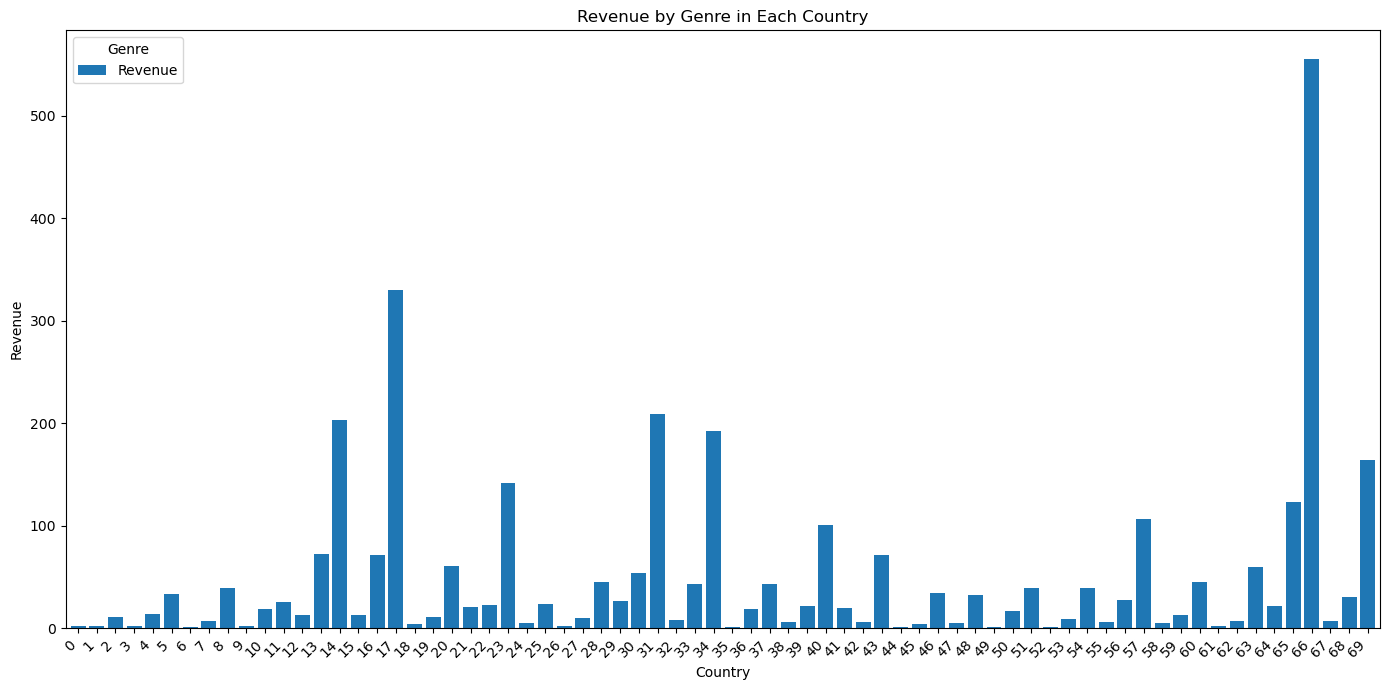

In [78]:
sql_query(q).plot(kind="bar", stacked=True, figsize=(14, 7), width=0.8)

plt.title("Revenue by Genre in Each Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Genre")
plt.tight_layout()
plt.show()